# CampaignScore — Ingestão e Preparação de Dados

> **Case de Machine Learning | Etapa 00 — Ingestão e preparação**

## Contexto do case

O **CampaignScore** é um case de Machine Learning integrante do projeto **CRM Intelligence**, inspirado em um desafio de processo seletivo para Analista de Dados de CRM, proposto por uma empresa brasileira do segmento de delivery de alimentos.

O cenário do desafio representa uma empresa fictícia do varejo alimentício que busca melhorar a rentabilidade de suas campanhas de marketing direto. Uma campanha piloto, realizada com 2.240 clientes, apresentou taxa de conversão de aproximadamente 15%, gerando uma receita inferior ao custo da ação e um resultado financeiro negativo de 3.046 unidades monetárias (MU).

Esse resultado motivou a busca por uma abordagem orientada por dados, capaz de identificar clientes com maior propensão a aceitar ofertas e direcionar os esforços de marketing de maneira mais eficiente. **O objetivo central do case é desenvolver soluções analíticas que contribuam para maximizar a rentabilidade das campanhas.**

Os dados utilizados são públicos e representam o cenário fictício proposto no desafio, não correspondendo a registros reais de clientes da empresa que o inspirou.

## Objetivo desta etapa

Este notebook estabelece a base curada que será utilizada pela EDA e pelas etapas analíticas seguintes. O processo contempla a ingestão do arquivo original, o diagnóstico de qualidade, as transformações determinísticas, os tratamentos definidos para valores extremos, a padronização de categorias, a tipagem das variáveis e a exportação dos dados e parâmetros de referência.

## Escopo e decisões de preparação

- O arquivo original contém **2.240 registros e 29 colunas**.
- `Age` é calculada a partir de `Year_Birth`, utilizando o ano da data máxima de cadastro como referência.
- `TenureDays` representa a diferença, em dias, entre `Dt_Customer` e a data máxima de cadastro encontrada na base.
- São removidos três registros com `Age` superior a 100 anos e oito registros identificados como outliers de `Income` pelo critério IQR de 1,5 vez a amplitude interquartil. A aplicação é sequencial: os limites de `Income` são calculados após o tratamento de `Age`.
- Os **24 valores ausentes de `Income` são preservados**. Não há imputação nesta etapa.
- `Marital_Status` é padronizada para reduzir categorias residuais e consolidar categorias consideradas semanticamente próximas. O mapeamento adotado é documentado no notebook.
- `Education` e `Marital_Status` são convertidas para o tipo `category`. Os tipos inteiros são reduzidos somente após validação de seus limites.
- `Year_Birth`, `Dt_Customer` e as colunas constantes são removidas da base curada após a criação das variáveis derivadas e a preservação dos parâmetros de negócio.
- Não são realizadas imputação, codificação para algoritmos, escalonamento, seleção de features, divisão entre treino e teste ou treinamento de modelos.

## Arquivos de saída

- **Base preparada em Parquet:** caminho definido por `PROCESSED_DATA`, consumida pelo notebook CampaignScore EDA e pelas etapas analíticas seguintes.
- **Parâmetros econômicos e referências temporais em JSON:** caminho definido por `BUSINESS_PARAMETERS`, utilizado posteriormente na avaliação econômica do Notebook 04 — Modelagem.

Os caminhos efetivos são centralizados no módulo `src.paths`.

## 1. Configuração do ambiente e ingestão

Esta seção importa as bibliotecas necessárias, define as configurações de exibição, carrega o arquivo original e confirma suas dimensões. A base bruta é preservada como fonte de referência; as transformações são aplicadas ao DataFrame de trabalho.

In [1]:
# Importação das bibliotecas e configuração dos caminhos do projeto
import sys
sys.path.insert(0, "..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.paths import RAW_DATA, PROCESSED_DATA, BUSINESS_PARAMETERS

In [2]:
# Configuração de exibição e visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.95
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
    "axes.axisbelow": True,
})

COLOR_PRIMARY = "#2878B5"
COLOR_SECONDARY = "#64748B"
COLOR_HIGHLIGHT = "#D97706"

### 1.1 Função auxiliar para cálculo dos limites IQR

A função `iqr_limits()` calcula os limites inferior e superior pelo método do intervalo interquartil (IQR), utilizando o fator de 1,5. Valores ausentes são ignorados no cálculo dos quartis. A função calcula os limites, mas não decide quais observações serão removidas; o critério operacional é definido separadamente para cada variável.

In [3]:
# Definição da função auxiliar para cálculo dos limites pelo método IQR
def iqr_limits(series):
    """Calcula os limites inferior e superior pelo método IQR (fator 1,5)."""
    values = pd.to_numeric(series, errors="coerce").dropna()

    if values.empty:
        raise ValueError("Não é possível calcular IQR de uma série sem valores válidos.")

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    return lower_limit, upper_limit

### 1.2 Carregamento do dataset original

O arquivo bruto é lido a partir do caminho configurado em `RAW_DATA`. A inspeção das primeiras linhas e das dimensões confirma se a ingestão preservou a estrutura esperada do dataset de origem.

In [4]:
# Ingestão do dataset original (camada raw)

df = pd.read_csv(
    RAW_DATA,
    sep="\t",
    encoding="utf-8"
)

TARGET = "Response"

display(df.head(3))
print(f"Formato inicial do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0


Formato inicial do dataset: 2240 linhas x 29 colunas


**Síntese da ingestão**

A ingestão carrega 2.240 clientes e 29 colunas. A variável `Response` é preservada como target, e `ID` é mantida como identificador para rastreabilidade dos registros ao longo da preparação e das análises posteriores.

## 2. Diagnóstico inicial da qualidade dos dados

O diagnóstico verifica tipos de dados, valores ausentes, cardinalidade, duplicatas e estatísticas descritivas. Essa etapa estabelece a condição inicial da base antes de qualquer transformação e registra os pontos que exigem tratamento.

### 2.1 Integridade, tipos e valores ausentes

O relatório apresenta, para cada coluna, o tipo, a quantidade e o percentual de valores ausentes e o número de valores distintos. Também são verificadas duplicatas completas e duplicidade na chave `ID`.

In [5]:
# Diagnóstico de integridade, tipos, valores ausentes e cardinalidade
quality_report = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_ausentes": df.isna().sum(),
    "percentual_ausente": (df.isna().mean() * 100).round(2),
    "valores_distintos": df.nunique(dropna=False),
}).sort_values(
    ["valores_ausentes", "valores_distintos"],
    ascending=[False, False]
)

print(f"Duplicatas completas: {df.duplicated().sum():,}")
print(f"IDs duplicados: {df['ID'].duplicated().sum():,}")
display(quality_report)

Duplicatas completas: 0
IDs duplicados: 0


,tipo,valores_ausentes,percentual_ausente,valores_distintos
Income,float64,24,1.07,1975
ID,int64,0,0.00,2240
MntWines,int64,0,0.00,776
Dt_Customer,str,0,0.00,663
MntMeatProducts,int64,0,0.00,558
MntGoldProds,int64,0,0.00,213
MntFishProducts,int64,0,0.00,182
MntSweetProducts,int64,0,0.00,177
MntFruits,int64,0,0.00,158
Recency,int64,0,0.00,100


### 2.2 Estatísticas descritivas iniciais

As estatísticas descritivas permitem identificar amplitudes, assimetrias aparentes e valores que merecem investigação. Identificadores e colunas constantes não são úteis para interpretar a distribuição das variáveis de negócio; por isso, a tabela prioriza atributos numéricos de perfil e comportamento.

In [6]:
# Estatísticas das variáveis numéricas de perfil e comportamento
numeric_cols = df.select_dtypes(include="number").columns.tolist()
exclude_from_describe = ["ID", "Z_CostContact", "Z_Revenue"]
descriptive_cols = [col for col in numeric_cols if col not in exclude_from_describe]

display(df[descriptive_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Year_Birth,"2,240.00","1,968.81",11.98,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00"
Income,"2,216.00","52,247.25","25,173.08","1,730.00","35,303.00","51,381.50","68,522.00","666,666.00"
Kidhome,"2,240.00",0.44,0.54,0.00,0.00,0.00,1.00,2.00
Teenhome,"2,240.00",0.51,0.54,0.00,0.00,0.00,1.00,2.00
Recency,"2,240.00",49.11,28.96,0.00,24.00,49.00,74.00,99.00
MntWines,"2,240.00",303.94,336.60,0.00,23.75,173.50,504.25,"1,493.00"
MntFruits,"2,240.00",26.30,39.77,0.00,1.00,8.00,33.00,199.00
MntMeatProducts,"2,240.00",166.95,225.72,0.00,16.00,67.00,232.00,"1,725.00"
MntFishProducts,"2,240.00",37.53,54.63,0.00,3.00,12.00,50.00,259.00
MntSweetProducts,"2,240.00",27.06,41.28,0.00,1.00,8.00,33.00,263.00


### 2.3 Distribuição da variável target

`Response` indica se o cliente aceitou a oferta apresentada na campanha piloto. A distribuição é registrada antes dos tratamentos para documentar a composição original da amostra e servir de referência para a comparação posterior.

In [7]:
# Distribuição inicial do target
initial_target_summary = pd.DataFrame({
    "Customers": df[TARGET].value_counts(dropna=False).sort_index(),
    "CustomerShare": df[TARGET].value_counts(normalize=True, dropna=False).sort_index() * 100,
})

display(initial_target_summary.style.format({
    "Customers": "{:,.0f}",
    "CustomerShare": "{:.2f}%"
}))

,Customers,CustomerShare
Response,,
0,"1,906",85.09%
1,334,14.91%


**Síntese do diagnóstico inicial**

A base contém 2.240 registros, sem duplicatas completas e sem IDs duplicados. `Income` apresenta 24 valores ausentes (1,07% da amostra); esses registros serão preservados. `Year_Birth` apresenta idade máxima calculada de 121 anos quando utilizado o ano de referência de 2014, e `Income` contém um valor máximo de 666.666 MU. Ambos serão investigados em etapas específicas.

A distribuição original de `Response` é de 1.906 clientes sem resposta positiva (85,09%) e 334 com resposta positiva (14,91%). Essa distribuição será comparada ao resultado após a curadoria.

## 3. Preservação dos parâmetros econômicos

`Z_CostContact` e `Z_Revenue` apresentam um único valor em todos os registros. Como não variam entre clientes, não contribuem para diferenciá-los na base analítica. Seus valores são preservados separadamente para uso na avaliação econômica das campanhas.

### 3.1 Identificação e validação das colunas constantes

A identificação é realizada de forma programática. Em seguida, cada coluna é validada para confirmar que contém exatamente um valor não nulo e que não possui ausências.

In [8]:
# Identificação de colunas constantes
CONSTANT_COLS = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("Colunas constantes identificadas:", CONSTANT_COLS)

for col in CONSTANT_COLS:
    unique_values = df[col].dropna().unique()

    assert len(unique_values) == 1, (
        f"{col} não possui exatamente um valor não nulo: {unique_values}"
    )
    assert df[col].notna().all(), f"{col} contém valores ausentes."

    print(f"{col}: {unique_values[0]}")

Colunas constantes identificadas: ['Z_CostContact', 'Z_Revenue']
Z_CostContact: 3
Z_Revenue: 11


### 3.2 Interpretação e preservação dos parâmetros

No contexto econômico descrito pelo case, `Z_CostContact` representa o custo de contato por cliente (3 MU) e `Z_Revenue` representa a receita por resposta positiva (11 MU). Esses parâmetros são preservados em um arquivo JSON, fora da matriz de atributos dos clientes.

Eles serão utilizados posteriormente em simulações econômicas. Não são features preditoras e não devem integrar a matriz de segmentação ou modelagem.

In [9]:
# Extração dos parâmetros econômicos constantes
business_values = {
    col: df[col].iloc[0].item()
    for col in CONSTANT_COLS
}

display(pd.Series(business_values, name="Value", dtype="int64").to_frame())

,Value
Z_CostContact,3
Z_Revenue,11


## 4. Tipagem temporal e criação de atributos

Esta seção converte a data de cadastro para o tipo apropriado e cria duas variáveis derivadas. A mesma data de referência é utilizada para calcular `Age` e `TenureDays`, mantendo coerência entre as transformações.

A referência adotada é a maior data de cadastro observada no dataset. Portanto, `TenureDays` representa o tempo decorrido entre o cadastro e essa data de referência; não deve ser interpretado como tempo de relacionamento até a data atual ou necessariamente até a data da campanha piloto.

### 4.1 Conversão da data de cadastro

`Dt_Customer` é convertida para `datetime` utilizando o formato dia-mês-ano presente no arquivo original. A conversão utiliza `errors="raise"` para interromper a execução caso exista algum valor fora do formato esperado.

In [10]:
# Conversão da coluna de cadastro
DATE_COL = "Dt_Customer"

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    format="%d-%m-%Y",
    errors="raise"
)

assert df[DATE_COL].notna().all(), f"A coluna {DATE_COL} contém valores ausentes."

### 4.2 Definição da referência e criação de `Age` e `TenureDays`

A data máxima de cadastro é utilizada como referência temporal. `Age` é calculada pela diferença entre o ano de referência e `Year_Birth`, resultando em uma estimativa que não considera dia e mês de nascimento. `TenureDays` corresponde à diferença em dias entre a data de referência e `Dt_Customer`.

In [11]:
# Definição da referência temporal
ref_date = df[DATE_COL].max()
ref_year = ref_date.year

# Criação das variáveis derivadas
df["Age"] = ref_year - df["Year_Birth"]
df["TenureDays"] = (ref_date - df[DATE_COL]).dt.days

# Validações das variáveis derivadas
assert df["Age"].notna().all()
assert (df["Age"] > 0).all(), "Foram encontrados valores inválidos em Age."
assert df["TenureDays"].notna().all()
assert (df["TenureDays"] >= 0).all(), "Foram encontrados valores negativos em TenureDays."

print(f"Data de referência: {ref_date.date()}")
print(f"Ano de referência para Age: {ref_year}")
display(df[["Year_Birth", DATE_COL, "Age", "TenureDays"]].head())

Data de referência: 2014-06-29
Ano de referência para Age: 2014


,Year_Birth,Dt_Customer,Age,TenureDays
0,1957,2012-09-04,57,663
1,1954,2014-03-08,60,113
2,1965,2013-08-21,49,312
3,1984,2014-02-10,30,139
4,1981,2014-01-19,33,161


**Síntese das transformações temporais**

A data máxima de cadastro observada é **29/06/2014**, e o ano de referência para o cálculo de `Age` é **2014**. A idade média inicial é de 45,19 anos, com mediana de 44 anos e máximo de 121 anos. `TenureDays` utiliza a mesma data de referência e permite representar o tempo decorrido desde o cadastro em dias.

## 5. Investigação e tratamento de valores extremos

Esta seção aplica os critérios de curadoria definidos para `Age` e `Income`. As exclusões são realizadas sequencialmente: primeiro são removidos os registros com idade superior a 100 anos; em seguida, os limites de `Income` são calculados sobre a base remanescente.

O método IQR identifica observações estatisticamente extremas, mas não comprova, isoladamente, que sejam erros. A decisão de tratamento considera os critérios operacionais adotados para este projeto.

### 5.1 Investigação e tratamento de `Age`

O boxplot permite visualizar a distribuição de idade e destacar observações acima do limite operacional de 100 anos. O método IQR é utilizado como diagnóstico complementar; os limites obtidos são comparados ao critério operacional definido para a curadoria.

In [12]:
# Estatísticas descritivas da idade antes do tratamento
display(df["Age"].describe())

count   2,240.00
mean       45.19
std        11.98
min        18.00
25%        37.00
50%        44.00
75%        55.00
max       121.00
Name: Age, dtype: float64

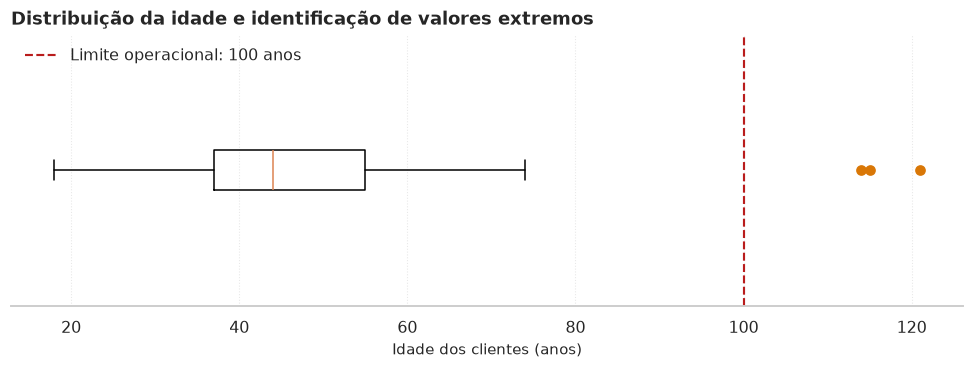

In [13]:
# Visualização da distribuição da idade e identificação de valores extremos
fig, ax = plt.subplots(figsize=(9, 3.5))

ax.boxplot(
    df["Age"].dropna(),
    orientation="horizontal",
    showfliers=True,
    flierprops={
        "marker": "o",
        "markerfacecolor": COLOR_HIGHLIGHT,
        "markeredgecolor": COLOR_HIGHLIGHT,
        "markersize": 6
    }
)

ax.axvline(
    100,
    color="#B91C1C",
    linestyle="--",
    linewidth=1.4,
    label="Limite operacional: 100 anos"
)
ax.set_yticks([])
ax.set_xlabel("Idade dos clientes (anos)")
ax.set_title("Distribuição da idade e identificação de valores extremos", loc="left")
ax.legend(frameon=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

In [14]:
# Identificação de valores extremos por IQR e aplicação do critério operacional
age_lower_limit, age_upper_limit = iqr_limits(df["Age"])
age_iqr_outliers = df["Age"].lt(age_lower_limit) | df["Age"].gt(age_upper_limit)
AGE_UPPER_LIMIT = 100
age_outlier_mask = df["Age"].gt(AGE_UPPER_LIMIT)

print(f"Limites IQR para Age: {age_lower_limit:.1f} a {age_upper_limit:.1f}")
print(f"Outliers identificados pelo IQR: {age_iqr_outliers.sum()}")
print(f"Registros com idade acima de {AGE_UPPER_LIMIT} anos: {age_outlier_mask.sum()}")

display(
    df.loc[age_outlier_mask, ["ID", "Year_Birth", "Age", TARGET]]
      .sort_values("Age", ascending=False)
)

Limites IQR para Age: 10.0 a 82.0
Outliers identificados pelo IQR: 3
Registros com idade acima de 100 anos: 3


,ID,Year_Birth,Age,Response
239,11004,1893,121,0
339,1150,1899,115,0
192,7829,1900,114,0


In [15]:
# Remoção dos registros com idade acima do limite operacional
rows_before_age = len(df)
df = df.loc[~age_outlier_mask].copy()
removed_age = rows_before_age - len(df)
rows_after_age = len(df)

print(f"Registros removidos por idade: {removed_age}")
print(f"Registros restantes: {rows_after_age:,}")

Registros removidos por idade: 3
Registros restantes: 2,237


**Interpretação do tratamento de `Age`**

O cálculo inicial identificou três clientes com idade superior a 100 anos. Os limites IQR foram de 10 a 82 anos, e as três observações acima de 100 anos também foram identificadas como outliers pelo critério estatístico.

Adotou-se o limite operacional de 100 anos para esta curadoria. Assim, três registros são removidos, reduzindo a base de 2.240 para **2.237 clientes**. O critério é aplicado ao registro completo, conforme a decisão de preparação definida para o projeto.

### 5.2 Investigação e tratamento de `Income`

`Income` apresenta 24 valores ausentes, que são preservados. A investigação concentra-se na distribuição dos valores informados e na identificação de observações acima do limite superior do IQR. O limite inferior também é calculado, embora valores negativos não sejam observados na distribuição apresentada.

In [16]:
# Estatísticas descritivas da renda após o tratamento de Age
display(df["Income"].describe())

count     2,213.00
mean     52,236.58
std      25,178.60
min       1,730.00
25%      35,246.00
50%      51,373.00
75%      68,487.00
max     666,666.00
Name: Income, dtype: float64

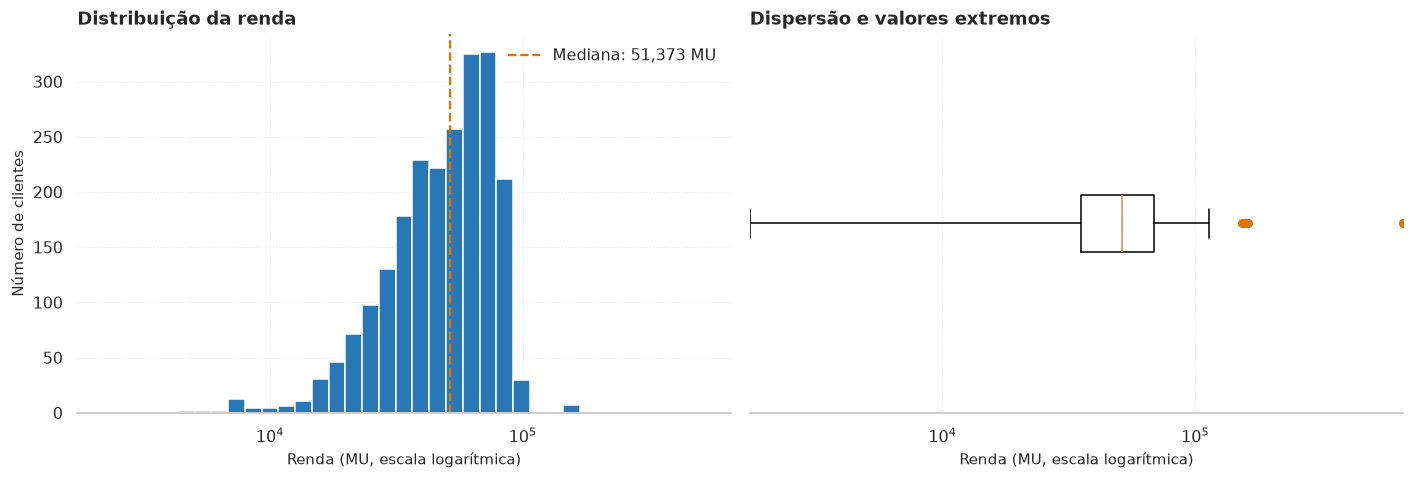

In [17]:
# Preparação dos valores válidos e definição de bins logarítmicos para comparação
income_before = df["Income"].dropna()
assert (income_before > 0).all(), "A escala logarítmica requer rendas positivas."

income_bins = np.logspace(
    np.log10(income_before.min()),
    np.log10(income_before.max()),
    40
)
income_xlim = (income_before.min(), income_before.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    income_before,
    bins=income_bins,
    color=COLOR_PRIMARY,
    edgecolor="white"
)
axes[0].set_xscale("log")
axes[0].set_xlim(income_xlim)
axes[0].axvline(
    income_before.median(),
    color=COLOR_HIGHLIGHT,
    linestyle="--",
    label=f"Mediana: {income_before.median():,.0f} MU"
)
axes[0].set_title("Distribuição da renda", loc="left")
axes[0].set_xlabel("Renda (MU, escala logarítmica)")
axes[0].set_ylabel("Número de clientes")
axes[0].legend(frameon=False)

axes[1].boxplot(
    income_before,
    orientation="horizontal",
    flierprops={
        "marker": "o",
        "markerfacecolor": COLOR_HIGHLIGHT,
        "markeredgecolor": COLOR_HIGHLIGHT,
        "markersize": 5
    }
)
axes[1].set_xscale("log")
axes[1].set_xlim(income_xlim)
axes[1].set_title("Dispersão e valores extremos", loc="left")
axes[1].set_xlabel("Renda (MU, escala logarítmica)")
axes[1].set_yticks([])

for ax in axes:
    sns.despine(ax=ax, left=True)

plt.tight_layout()
plt.show()

### 5.3 Aplicação do critério IQR em `Income`

Os limites são calculados sobre os valores não ausentes de `Income` na base após o tratamento de idade. O critério adotado remove as oito observações acima do limite superior. Os 24 valores ausentes não são classificados como outliers e permanecem na base.

In [18]:
# Identificação de valores extremos pelo método IQR
income_lower_limit, income_upper_limit = iqr_limits(df["Income"])
income_outlier_mask = (
    df["Income"].lt(income_lower_limit)
    | df["Income"].gt(income_upper_limit)
)

print(
    f"Limites IQR de Income: "
    f"{income_lower_limit:,.2f} a {income_upper_limit:,.2f} MU"
)
print(f"Outliers identificados pelo IQR: {income_outlier_mask.sum()}")
print(f"Valores ausentes preservados: {df['Income'].isna().sum()}")

display(
    df.loc[income_outlier_mask, ["ID", "Income", TARGET]]
      .sort_values("Income", ascending=False)
)

Limites IQR de Income: -14,615.50 a 118,348.50 MU
Outliers identificados pelo IQR: 8
Valores ausentes preservados: 24


,ID,Income,Response
2233,9432,"666,666.00",0
617,1503,"162,397.00",0
687,1501,"160,803.00",0
1300,5336,"157,733.00",0
164,8475,"157,243.00",0
1653,4931,"157,146.00",0
2132,11181,"156,924.00",0
655,5555,"153,924.00",0


In [19]:
# Remoção dos registros identificados como outliers de Income
rows_before_income = len(df)
df = df.loc[~income_outlier_mask].copy()
removed_income = rows_before_income - len(df)
rows_after_income = len(df)

print(f"Registros removidos por Income: {removed_income}")
print(f"Registros restantes: {rows_after_income:,}")

Registros removidos por Income: 8
Registros restantes: 2,229


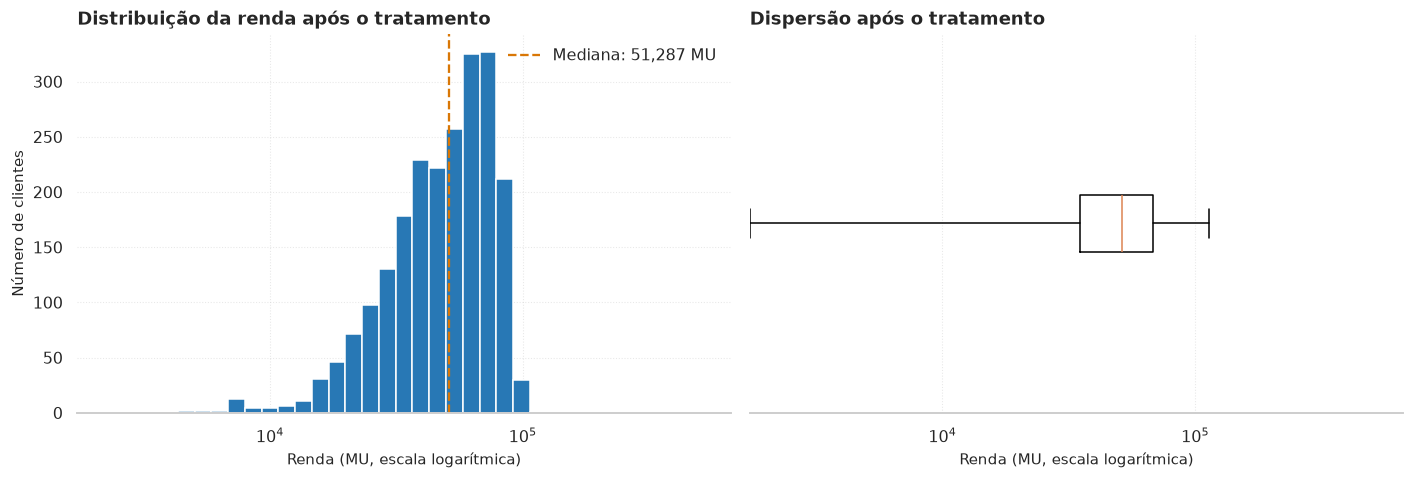

In [20]:
# Comparação da distribuição de renda após o tratamento, mantendo a mesma escala e os mesmos bins
income_after = df["Income"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    income_after,
    bins=income_bins,
    color=COLOR_PRIMARY,
    edgecolor="white"
)
axes[0].set_xscale("log")
axes[0].set_xlim(income_xlim)
axes[0].axvline(
    income_after.median(),
    color=COLOR_HIGHLIGHT,
    linestyle="--",
    label=f"Mediana: {income_after.median():,.0f} MU"
)
axes[0].set_title("Distribuição da renda após o tratamento", loc="left")
axes[0].set_xlabel("Renda (MU, escala logarítmica)")
axes[0].set_ylabel("Número de clientes")
axes[0].legend(frameon=False)

axes[1].boxplot(
    income_after,
    orientation="horizontal",
    flierprops={
        "marker": "o",
        "markerfacecolor": COLOR_HIGHLIGHT,
        "markeredgecolor": COLOR_HIGHLIGHT,
        "markersize": 5
    }
)
axes[1].set_xscale("log")
axes[1].set_xlim(income_xlim)
axes[1].set_title("Dispersão após o tratamento", loc="left")
axes[1].set_xlabel("Renda (MU, escala logarítmica)")
axes[1].set_yticks([])

for ax in axes:
    sns.despine(ax=ax, left=True)

plt.tight_layout()
plt.show()

**Interpretação do tratamento de `Income`**

Após a remoção dos três registros de idade, a renda apresentava 2.213 valores informados e 24 ausentes. O método IQR produziu limites de **−14.615,50 a 118.348,50 MU** e identificou oito observações acima do limite superior.

Os oito registros são removidos conforme o critério adotado. A base passa de 2.237 para **2.229 clientes**. Os 24 valores ausentes de `Income` são preservados. As visualizações anterior e posterior utilizam escala logarítmica e os mesmos limites e intervalos de histograma, permitindo comparação visual consistente.

O método IQR identifica valores extremos estatísticos; a decisão de removê-los é uma regra de curadoria definida para este projeto, não uma demonstração de que cada observação seja necessariamente um erro.

## 6. Tratamento de variáveis categóricas

Esta seção aplica as regras de consolidação de `Marital_Status` definidas para o projeto e converte as variáveis categóricas para um tipo de dado apropriado. As operações organizam as categorias e o schema da base, sem realizar codificação numérica para algoritmos.

### 6.1 Consolidação de `Marital_Status`

O mapeamento agrupa `Married` e `Together` em `Partnered`, representando clientes em um relacionamento sem distinguir a formalização da união. As categorias `Alone`, `Absurd` e `YOLO` são agrupadas em `Single`, considerando a baixa frequência de `Absurd` e `YOLO` e a interpretação adotada para o campo. `Divorced`, `Widow` e `Single` permanecem sem alteração.

As categorias `Absurd` e `YOLO` são respostas não padronizadas; sua classificação como `Single` é uma decisão interpretativa de curadoria, não uma informação confirmada sobre o estado civil real desses clientes.

In [21]:
# Distribuição original de Marital_Status após a higienização textual
marital_status_before = (
    df["Marital_Status"]
    .value_counts(dropna=False)
    .rename_axis("Marital_Status")
    .to_frame("Customers")
)
marital_status_before["CustomerShare"] = (
    marital_status_before["Customers"] / len(df) * 100
)

display(marital_status_before.style.format({
    "Customers": "{:,.0f}",
    "CustomerShare": "{:.2f}%"
}))

,Customers,CustomerShare
Marital_Status,,
Married,861,38.63%
Together,575,25.80%
Single,479,21.49%
Divorced,230,10.32%
Widow,77,3.45%
Alone,3,0.13%
Absurd,2,0.09%
YOLO,2,0.09%


In [22]:
# Consolidação semântica de Marital_Status
marital_mapping = {
    "Married": "Partnered",
    "Together": "Partnered",
    "Alone": "Single",
    "Absurd": "Single",
    "YOLO": "Single"
}

df["Marital_Status"] = df["Marital_Status"].replace(marital_mapping)

expected_marital_categories = {"Partnered", "Single", "Divorced", "Widow"}
observed_marital_categories = set(df["Marital_Status"].dropna().unique())

unexpected_marital_categories = observed_marital_categories - expected_marital_categories
assert not unexpected_marital_categories, (
    f"Categorias não mapeadas em Marital_Status: {unexpected_marital_categories}"
)

marital_status_after = (
    df["Marital_Status"]
    .value_counts(dropna=False)
    .rename_axis("Marital_Status")
    .to_frame("Customers")
)
marital_status_after["CustomerShare"] = (
    marital_status_after["Customers"] / len(df) * 100
)

display(marital_status_after.sort_values("Customers", ascending=False).style.format({
    "Customers": "{:,.0f}",
    "CustomerShare": "{:.2f}%"
}))

,Customers,CustomerShare
Marital_Status,,
Partnered,"1,436",64.42%
Single,486,21.80%
Divorced,230,10.32%
Widow,77,3.45%


**Resultado da padronização de `Marital_Status`**

A padronização reduz oito categorias originais para quatro:

- `Partnered`: 1.436 clientes (64,42%).
- `Single`: 486 clientes (21,80%).
- `Divorced`: 230 clientes (10,32%).
- `Widow`: 77 clientes (3,45%).

A consolidação privilegia uma representação mais simples para as análises de perfil. A informação original continua disponível na camada bruta, permitindo revisar o mapeamento se necessário.

### 6.2 Conversão para tipos categóricos

Após a consolidação de `Marital_Status`, as variáveis `Education` e `Marital_Status` são convertidas para o tipo `category`. Essa tipagem representa adequadamente a natureza categórica das variáveis e organiza o schema da base para consumo pelas etapas seguintes. A conversão não equivale à codificação numérica exigida por algoritmos.

In [23]:
# Conversão de variáveis textuais para category
categorical_cols = ["Education", "Marital_Status"]
df[categorical_cols] = df[categorical_cols].astype("category")

print(df[categorical_cols].dtypes)

Education         category
Marital_Status    category
dtype: object


## 7. Remoção de colunas e otimização dos tipos numéricos

Após a criação das variáveis derivadas, são removidas as colunas que não precisam permanecer na base curada. Em seguida, os tipos inteiros são reduzidos após a validação da integridade dos valores e dos limites de representação.

### 7.1 Remoção de colunas de origem e constantes

`Year_Birth` e `Dt_Customer` são removidas porque suas informações relevantes já estão representadas por `Age` e `TenureDays`. As colunas constantes também são excluídas, pois seus valores foram preservados nos parâmetros de negócio.

In [24]:
# Remoção das colunas de origem e das colunas constantes
cols_to_drop = ["Year_Birth", DATE_COL] + CONSTANT_COLS

missing_drop_cols = set(cols_to_drop) - set(df.columns)
assert not missing_drop_cols, f"Colunas esperadas para remoção não encontradas: {missing_drop_cols}"

df = df.drop(columns=cols_to_drop)
df = df.reset_index(drop=True)
print(f"Colunas removidas: {cols_to_drop}")

Colunas removidas: ['Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue']


### 7.2 Redução segura dos tipos inteiros

As variáveis inteiras são agrupadas por tipo de destino. Antes da conversão, uma função auxiliar valida a ausência de valores nulos, a integralidade dos dados e a compatibilidade com os limites do tipo escolhido.

`Income` permanece como `float64` para preservar os valores ausentes, enquanto `ID` é mantida como `int64`, sem redução de tipo.

In [25]:
# Medição de memória antes da otimização dos tipos numéricos
memory_before_optimization = df.memory_usage(deep=True).sum()

int8_cols = [
    "Kidhome",
    "Teenhome",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Complain",
    "Response",
    "Age",
]

int16_cols = [
    "Recency",
    "TenureDays",
]

int32_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]

integer_dtype_map = {
    **{col: "int8" for col in int8_cols},
    **{col: "int16" for col in int16_cols},
    **{col: "int32" for col in int32_cols},
}


# Validação e conversão dos tipos inteiros

for col, dtype in integer_dtype_map.items():
    values = df[col]
    limits = np.iinfo(dtype)

    assert values.notna().all(), f"{col} contém valores ausentes."
    assert values.mod(1).eq(0).all(), f"{col} contém valores não inteiros."
    assert values.min() >= limits.min and values.max() <= limits.max, (
        f"{col} excede os limites de {dtype}."
    )

    df[col] = values.astype(dtype)

In [26]:
# Cálculo da redução de memória após a otimização dos tipos numéricos
memory_after_optimization = df.memory_usage(deep=True).sum()

memory_reduction = (
    (memory_before_optimization - memory_after_optimization)
    / memory_before_optimization * 100
)

print(f"Memória antes da otimização: {memory_before_optimization:,.0f} bytes")
print(f"Memória após a otimização: {memory_after_optimization:,.0f} bytes")
print(f"Redução de memória: {memory_reduction:.2f}%")

Memória antes da otimização: 450,524 bytes
Memória após a otimização: 136,235 bytes
Redução de memória: 69.76%


### 7.3 Inspeção do schema preparado

A inspeção final dos tipos confirma a representação das variáveis categóricas e numéricas. Também permite verificar se as reduções de tipo foram aplicadas sem alterar a estrutura esperada.

In [27]:
# Inspeção do DataFrame após tipagem e otimização
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2229 entries, 0 to 2228
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   ID                   2229 non-null   int64   
 1   Education            2229 non-null   category
 2   Marital_Status       2229 non-null   category
 3   Income               2205 non-null   float64 
 4   Kidhome              2229 non-null   int8    
 5   Teenhome             2229 non-null   int8    
 6   Recency              2229 non-null   int16   
 7   MntWines             2229 non-null   int32   
 8   MntFruits            2229 non-null   int32   
 9   MntMeatProducts      2229 non-null   int32   
 10  MntFishProducts      2229 non-null   int32   
 11  MntSweetProducts     2229 non-null   int32   
 12  MntGoldProds         2229 non-null   int32   
 13  NumDealsPurchases    2229 non-null   int8    
 14  NumWebPurchases      2229 non-null   int8    
 15  NumCatalogPurchases  2229 non-nu

## 8. Validação final e exportação dos artefatos

Esta etapa verifica a integridade da base curada e exporta os dados preparados em Parquet e os parâmetros econômicos e as referências temporais em JSON.

### 8.1 Validações finais

As verificações confirmam a quantidade esperada de registros, a unicidade de `ID`, a integridade de `Response`, a preservação dos valores ausentes de `Income`, os limites operacionais de `Age` e `TenureDays`, as categorias de `Marital_Status` e a remoção das colunas previstas.

In [28]:
# Validação final da base curada

assert len(df) == 2229, f"Quantidade final inesperada: {len(df)}"
assert df["ID"].is_unique, "Foram encontrados IDs duplicados."
assert df[TARGET].notna().all(), "Response contém valores ausentes."
assert set(df[TARGET].unique()).issubset({0, 1}), "Response contém valores fora de {0, 1}."
assert df["Income"].isna().sum() == 24, "Quantidade inesperada de ausências em Income."
assert df["Age"].between(18, 100).all(), "Age contém valores fora do intervalo definido."
assert df["TenureDays"].ge(0).all(), "TenureDays contém valores negativos."
assert set(df["Marital_Status"].cat.categories) == {"Divorced", "Partnered", "Single", "Widow"}

for col in cols_to_drop:
    assert col not in df.columns, f"A coluna {col} deveria ter sido removida."

print(f"Registros finais: {len(df):,}")
print(f"Colunas finais: {len(df.columns)}")
print(f"Valores ausentes em Income: {df['Income'].isna().sum()}")

Registros finais: 2,229
Colunas finais: 27
Valores ausentes em Income: 24


### 8.2 Exportação dos artefatos

A base curada é exportada em formato Parquet para utilização nas etapas seguintes. Os parâmetros econômicos e as referências temporais utilizados na preparação são registrados em um arquivo JSON para consumo posterior.

In [29]:
# Organização dos parâmetros econômicos e das referências temporais para exportação
business_parameters = {
    "economic_parameters": {
        "unit": "MU",
        "values": business_values,
        "definitions": {
            "Z_CostContact": "Custo de contato por cliente",
            "Z_Revenue": "Receita por conversão positiva"
        }
    },
    "reference": {
        "reference_date": ref_date.strftime("%Y-%m-%d"),
        "reference_year": int(ref_year)
    }
}

In [30]:
# Exportação dos artefatos
df.to_parquet(PROCESSED_DATA, index=False)

with open(BUSINESS_PARAMETERS, "w", encoding="utf-8") as file:
    json.dump(
        business_parameters,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Base curada e parâmetros de negócio exportados com sucesso.")

Base curada e parâmetros de negócio exportados com sucesso.


## Conclusão

A preparação parte de 2.240 registros e entrega uma base curada com **2.229 clientes e 27 colunas**. Foram removidos três registros com `Age` superior a 100 anos e oito registros identificados como outliers de `Income` pelo critério IQR de 1,5 vez a amplitude interquartil. Os 24 valores ausentes de `Income` foram preservados.

As variáveis `Age` e `TenureDays` foram criadas utilizando a referência temporal de 29/06/2014. `Marital_Status` foi consolidada em quatro categorias (`Partnered`, `Single`, `Divorced` e `Widow`), e as variáveis categóricas e numéricas receberam tipagem adequada para o consumo analítico.

`Year_Birth`, `Dt_Customer` e as colunas constantes foram removidas da base curada. Os parâmetros econômicos e as referências temporais foram preservados separadamente em JSON.

O resultado desta etapa é uma base estruturada e preparada para a EDA e as análises subsequentes. A seleção definitiva de features, a imputação, a codificação para algoritmos, o escalonamento, a divisão entre treino e teste e a modelagem permanecem fora do escopo deste notebook.